# CA3

### Imports

In [ ]:
# %pip install ucimlrepo # don't know why but I need this to properly get it to run, at least for the first run
# so if the operation stops remove the "#" and try again 
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
import pandas as pd 
from ucimlrepo import fetch_ucirepo 


### dowloading the data

the example given from the site https://archive.ics.uci.edu/dataset/186/wine%2Bquality
Where the data originates from, though do take note that that the wine_quality has been changed to wine_q in case we want to use the term wine_quality later. 

In [ ]:
# Downloading of the data through internal files
wine_train = pd.read_csv("train.csv")
wine_test = pd.read_csv("test.csv")
 
# printing the data to get a look
print(wine_train) 

     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0              7.8             0.610         0.29            1.60      0.114   
1              8.4             1.035         0.15            6.00      0.073   
2              8.1             0.290         0.36            2.20      0.048   
3              5.2             0.340         0.00            1.80      0.050   
4             15.6             0.645         0.49            4.20      0.095   
..             ...               ...          ...             ...        ...   
830            8.2             0.320         0.42            2.30      0.098   
831            6.0             0.510         0.00            2.10      0.064   
832            7.2             0.725         0.05            4.65      0.086   
833            7.3             0.835         0.03            2.10      0.092   
834            8.7             0.630         0.28            2.70      0.096   

     free sulfur dioxide  total sulfur 

In [ ]:
# To get a look at wine test as well
print(wine_test)

     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0              7.0              0.69         0.07             2.5      0.091   
1              6.4              0.47         0.40             2.4      0.071   
2              7.9              0.53         0.24             2.0      0.072   
3              7.6              0.41         0.24             1.8      0.080   
4              8.1              0.87         0.00             2.2      0.084   
..             ...               ...          ...             ...        ...   
204            7.0              0.64         0.02             2.1      0.067   
205            8.0              0.60         0.22             2.1      0.080   
206            7.6              0.31         0.34             2.5      0.082   
207            8.0              0.50         0.39             2.6      0.082   
208           11.9              0.39         0.69             2.8      0.095   

     free sulfur dioxide  total sulfur 

In [39]:
# to double check if we have the right file, and to display it's size
print("Training data size: ", wine_train.shape)
print("test data size: ", wine_test.shape)
print(wine_train.columns.tolist())



Training data size:  (835, 13)
test data size:  (209, 12)
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']


### Data exploration and visualisation

Fixed Acidity: A measure of the non-volatile acids present in the wine. Acidity contributes to the wine's taste and overall characteristics.

Volatile Acidity: A measure of volatile acids in the wine. Higher levels can negatively affect the taste and quality of the wine.

Citric Acid: The amount of citric acid present in the wine. Citric acid can contribute to freshness and flavor.

Residual Sugar: The amount of sugar remaining in the wine after fermentation. Higher values indicate sweeter wines.

Chlorides: The concentration of salt-related compounds in the wine. Higher levels may negatively affect wine quality.

Free Sulfur Dioxide: The amount of free sulfur dioxide in the wine. It is commonly used as a preservative and helps prevent oxidation.

Total Sulfur Dioxide: The total amount of sulfur dioxide, including both free and bound forms.

Density: The density of the wine. This can be related to the wine's alcohol and sugar content.

pH: A measure of the acidity of the wine. Lower pH values indicate higher acidity.

Sulphates: The concentration of sulphates in the wine. Sulphates can contribute to wine stability and preservation.

Alcohol: The alcohol content of the wine. Alcohol level can be related to both the characteristics and quality of the wine.

Quality (target): Binary indicator of wine quality, with 1 representing "Good" wine and 0 representing "Bad" wine.


### Data cleaning

In [42]:
print(wine_train.isna().sum().sum())
print(wine_test.isna().sum().sum())
#This should give 0 so there is no missing numbers or information, neverhteles let's double check with missing values

0
0


### Data preprocessing and visualisation

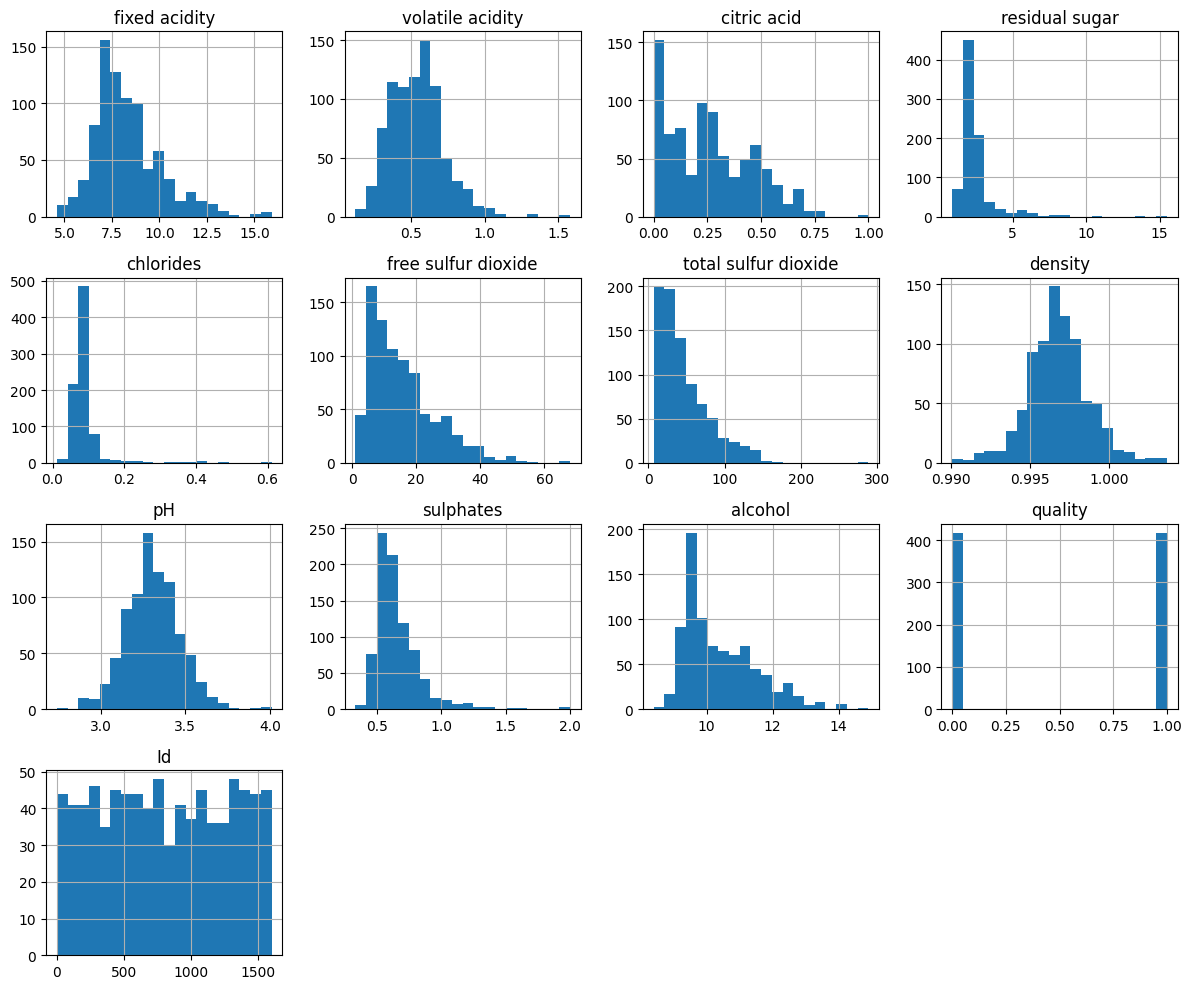

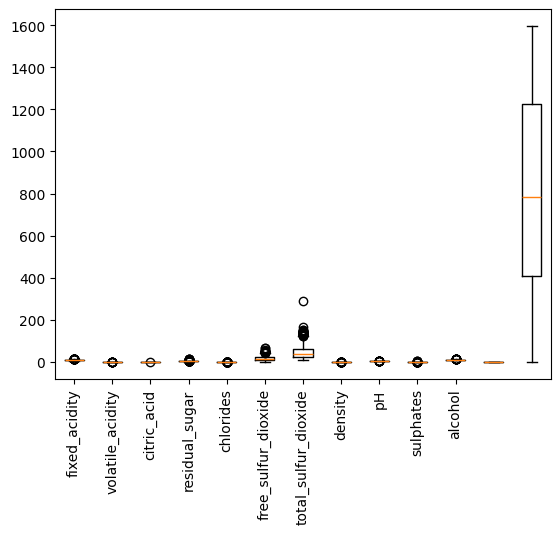

In [44]:
# To display a visualisation of the the various feautures 
wine_train.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

# Displaying the outliers by directly showing where different samples cluster together, and by extension the outliers
plt.boxplot(wine_train)
plt.xticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 
           ["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides", 
            "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol"], 
            rotation=90)
plt.show()


As can be seen in the boxes, a lot of the data, even most if not all of some feautures falls outside of the "average" meaning removing the outliers will be harder than just removing those that fall outside the average. As there are still clear outliers.


**Discusion**:
In regards to outliers, there can be made an argument that in this instance it would be unecasary to remove them. As we do not know the standards of which these tests were carried out in. Or if these outliers are even that far fetched in regards to bigger samples of wine. They would also simply be filed away into the lower quality catagori if kept. 

In [45]:
# Gives each item inside the dataframe a score based on how far it is from the mean through z = (x-mu)/sigma
z_scores = (wine_train - wine_train.mean()) / wine_train.std(ddof=0)

# Checks if the z score is above or under the average by 3 through using absolute values
outliers = z_scores.abs() > 3

print("Outliers per feature:")
print(outliers.sum())

Outliers per feature:
fixed acidity            7
volatile acidity         4
citric acid              1
residual sugar          16
chlorides               16
free sulfur dioxide     11
total sulfur dioxide     6
density                  8
pH                       4
sulphates               13
alcohol                  7
quality                  0
Id                       0
dtype: int64


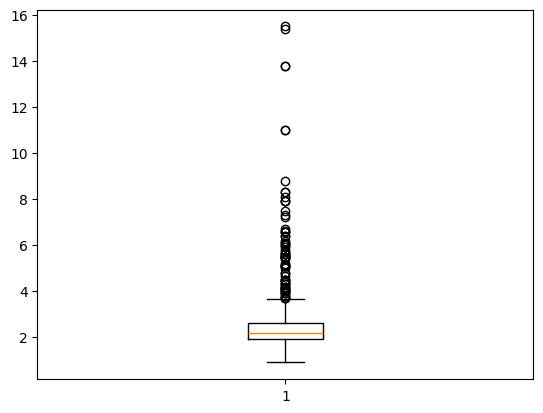

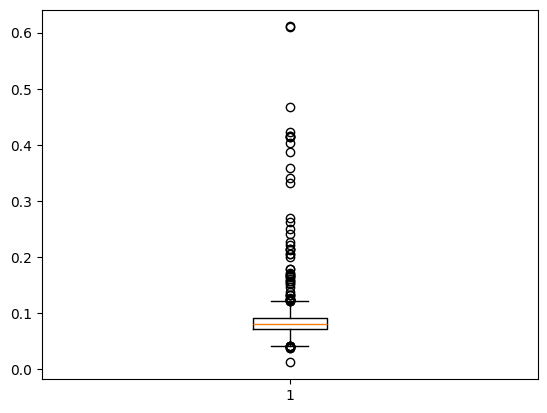

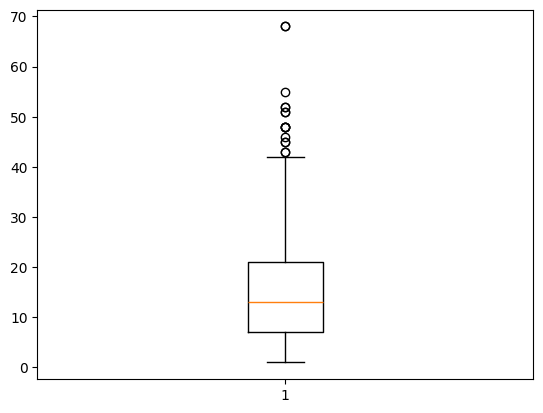

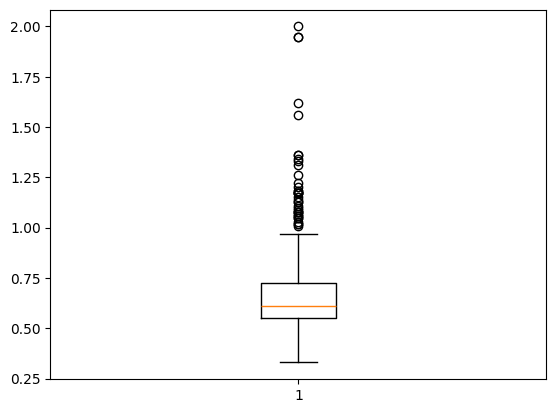

In [50]:
# We'll take a deeper look at residual sugar, chlorides, free sulfur dioxide and sulphates
# since they are much higher than the rest
plt.boxplot(wine_train["residual sugar"])
plt.show()

plt.boxplot(wine_train["chlorides"])
plt.show()

plt.boxplot(wine_train["free sulfur dioxide"])
plt.show()

plt.boxplot(wine_train["sulphates"])
plt.show()

**Discusion**:
there can be made another argument on wether these four should have the limits on their Z_scores heightened to reduce their outlier count. Though this would in turn produce a new variable in the form of ununinform fitting

In [ ]:
# Identify rows containing at least one outlier
outlier_rows = outliers.any(axis=1)

# To make sure we aren't removing too much data, which 73 from 835 is a acceptilbe number 
print(f"Rows to remove: {outlier_rows.sum()}")

# Filtering the data
wine_train_clean = wine_train.loc[~outlier_rows].copy()

Rows to remove: 73


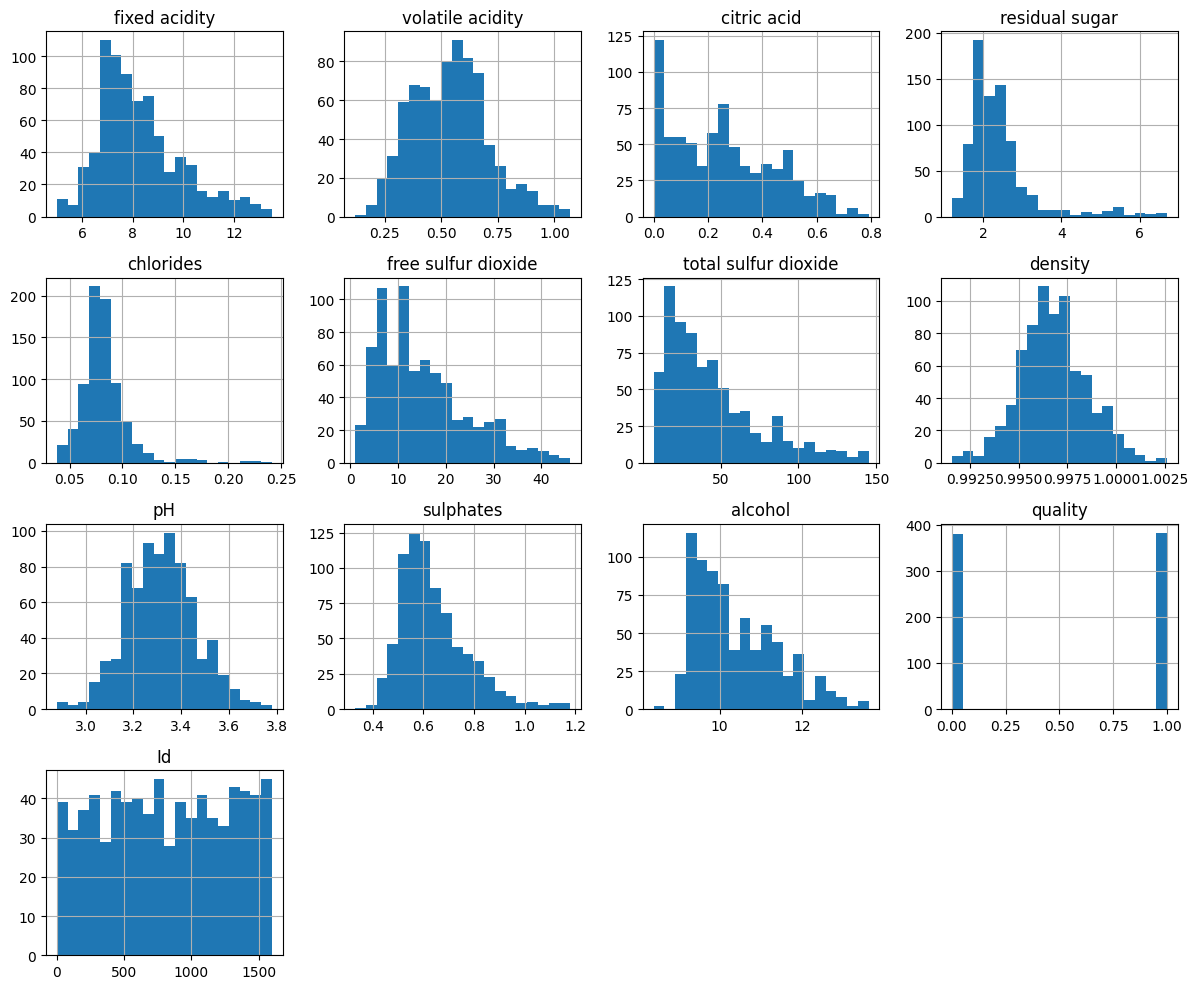

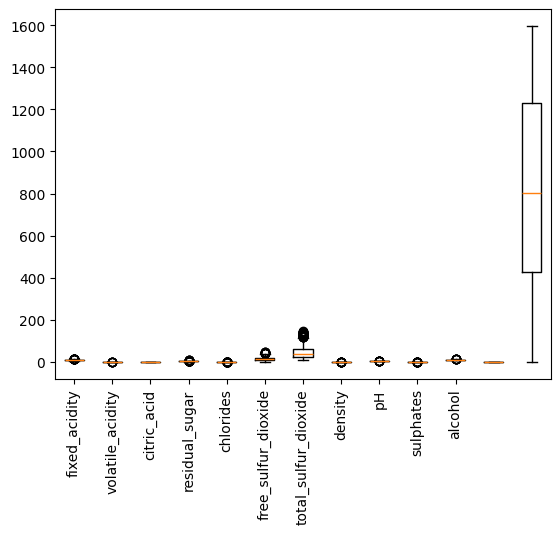

In [51]:
# Displaying the graphs again to visually confirm that the outliers have been removed. No need for thourougnes
wine_train_clean.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

plt.boxplot(wine_train_clean)
plt.xticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 
           ["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides", 
            "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol"], 
            rotation=90)
plt.show()

### Modelling

### Final evaluation

### Kaggle submission

In [18]:
#this was just a example provided by the profesor, so up for editing to better suit our work!!

y_test = model.predict(X_test2_scaled)
y_test = pd.DataFrame(y_test2, columns=["Quality"])
y_test.index.name = "ID"
y_test[['Quality']].to_csv("submission.csv")

NameError: name 'model' is not defined